# 02 · Experimento de ablación: ¿aportan las variables de entrenamiento?

**Pregunta:** ¿cuánto mejora la predicción de `velocity_kmh` al añadir variables de entrenamiento a variables demográficas y de carrera pre-race?

- **Modelo A (sin entrenamiento):** `age`, `bmi`, `female`, `footwear`, `injury`, `distancia_km`
- **Modelo B (con entrenamiento):** A + `typical`, `max`, `sprint`, `tempo`, `endurancecat`, `endurancespeed`

Ambos modelos usan la misma arquitectura MLP, los mismos hiperparámetros y las mismas particiones. Sólo cambian las features.

**Excluidas de ambos modelos:** `forma_fisica` y `dificultad` (se reportan el día de la carrera y `velocity_kmh` ya se ajusta por dificultad), `id` (identificador) y `tiempo_ajustado_s` (de ella sale el target).

**Reglas de validación:**
- Partición por corredor (`id`) para evitar fuga entre entrenamiento y evaluación.
- Escaladores ajustados sólo con train.
- Las comparaciones usan **validación**. El conjunto de **test queda reservado** y no se toca en este notebook.
- Varias semillas, reportando media ± desviación y la diferencia pareada B − A por semilla.


## 0. Configuración e imports

In [13]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
SEEDS = [0, 1, 2, 3, 4]          # semillas para el MLP
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "df_long.parquet").exists():
            return p
    raise FileNotFoundError("No se encontró data/processed/df_long.parquet")

ROOT = find_repo_root()
RESULTS = ROOT / "resultados"
RESULTS.mkdir(exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

print(f"Raíz: {ROOT}\nDevice: {DEVICE}\nTorch {torch.__version__}")

Raíz: /Users/mirandaurbansolano/GitHub/tc3009C-deep-learning-project
Device: cpu
Torch 2.15.0


## 1. Carga y verificación

In [14]:
df = pd.read_parquet(ROOT / "data" / "processed" / "df_long.parquet")
print(df.shape)

assert df["velocity_kmh"].notna().all()
assert df.drop(columns=["distancia"]).isnull().sum().sum() == 0
v_recalc = df["distancia_km"] / (df["tiempo_ajustado_s"] / 3600)
assert (v_recalc - df["velocity_kmh"]).abs().max() < 1e-9
print("Integridad OK: sin nulos y fórmula de velocidad verificada.")

(5153, 18)
Integridad OK: sin nulos y fórmula de velocidad verificada.


## 2. Definición de features

`distancia_km` entra en ambos modelos como control: se conoce antes de correr. Nota: `velocity_kmh` = `distancia_km` / tiempo, así que la distancia es parte de la relación con el target, pero no es una fuga.


In [15]:
DEMO = ["age", "bmi", "female"]
CARRERA_PRE = ["distancia_km"]
OTRAS = ["footwear", "injury"]          # injury es histórico; footwear es atributo previo
ENTRENO = ["typical", "max", "sprint", "tempo", "endurancecat", "endurancespeed"]

FEATS_A = DEMO + CARRERA_PRE + OTRAS
FEATS_B = FEATS_A + ENTRENO
TARGET = "velocity_kmh"

EXCLUIDAS = {"forma_fisica", "dificultad", "tiempo_ajustado_s", "id", "distancia"}
assert not (set(FEATS_B) & EXCLUIDAS), "Hay una feature excluida en el modelo B"
assert not (set(FEATS_A) & EXCLUIDAS), "Hay una feature excluida en el modelo A"
print("Modelo A:", FEATS_A)
print("Modelo B:", FEATS_B)

Modelo A: ['age', 'bmi', 'female', 'distancia_km', 'footwear', 'injury']
Modelo B: ['age', 'bmi', 'female', 'distancia_km', 'footwear', 'injury', 'typical', 'max', 'sprint', 'tempo', 'endurancecat', 'endurancespeed']


## 3. Partición por corredor (train / val / test)

In [16]:
def split_by_runner(d, val_size=0.15, test_size=0.15, seed=SEED):
    gss1 = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trval_idx, test_idx = next(gss1.split(d, groups=d["id"]))
    trval = d.iloc[trval_idx]
    gss2 = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    tr_idx, val_idx = next(gss2.split(trval, groups=trval["id"]))
    return trval.iloc[tr_idx], trval.iloc[val_idx], d.iloc[test_idx]

train, val, test = split_by_runner(df)

ids = {k: set(x["id"]) for k, x in zip(["train", "val", "test"], [train, val, test])}
assert not (ids["train"] & ids["val"]), "Fuga: corredores en train y val"
assert not (ids["train"] & ids["test"]), "Fuga: corredores en train y test"
assert not (ids["val"] & ids["test"]), "Fuga: corredores en val y test"

part = pd.DataFrame({
    "split": ["train", "val", "test"],
    "filas": [len(train), len(val), len(test)],
    "corredores": [len(ids["train"]), len(ids["val"]), len(ids["test"])],
})
display(part)
print("Sin corredores compartidos entre particiones.")

,split,filas,corredores
0,train,3597,1514
1,val,778,325
2,test,778,325


Sin corredores compartidos entre particiones.


## 4. Modelos

MLP con la misma arquitectura que en `01_eda_y_baselines.ipynb`: capas 64-32, ReLU, dropout 0.2, Adam con weight decay y pérdida MSE. Épocas fijas, sin selección por validación, para que A y B reciban exactamente el mismo entrenamiento.


In [17]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


HP = dict(epochs=80, lr=1e-3, weight_decay=1e-4, batch_size=64)


def train_mlp(Xtr, ytr, Xva, yva, seed, hp=HP):
    set_seed(seed)
    model = MLP(Xtr.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.tensor(Xtr, dtype=torch.float32),
                                      torch.tensor(ytr, dtype=torch.float32)),
                        batch_size=hp["batch_size"], shuffle=True)
    Xva_t = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    yva_t = torch.tensor(yva, dtype=torch.float32, device=DEVICE)
    hist = {"train": [], "val": []}
    for _ in range(hp["epochs"]):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        hist["train"].append(tot / n)
        model.eval()
        with torch.no_grad():
            hist["val"].append(loss_fn(model(Xva_t), yva_t).item())
    return model, hist


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()


def metrics(y, p):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAE": float(mean_absolute_error(y, p)),
        "R2": float(r2_score(y, p)),
    }

## 5. Escalado (ajustado sólo con train)

In [18]:
def prepare(feats):
    sc = StandardScaler().fit(train[feats])          # sólo train
    f = lambda d: sc.transform(d[feats])
    return f(train), f(val), f(test)

XA_tr, XA_va, XA_te = prepare(FEATS_A)
XB_tr, XB_va, XB_te = prepare(FEATS_B)
y_tr = train[TARGET].values
y_va = val[TARGET].values
y_te = test[TARGET].values   # reservado: no se usa en este notebook
print("Escaladores ajustados sólo con train.")

Escaladores ajustados sólo con train.


## 6. Línea base de referencia y Ridge

- **Media:** predice siempre la media de train. Es el piso de comparación.
- **Ridge A / B:** modelos lineales con las mismas features. Sirven para separar cuánto aporta lo lineal de cuánto aporta lo no lineal del MLP.


In [19]:
rows = []

mean_pred = np.full_like(y_va, y_tr.mean())
rows.append({"modelo": "Media (referencia)", "semilla": None, **metrics(y_va, mean_pred)})

for name, (Xtr, Xva) in {"Ridge A": (XA_tr, XA_va), "Ridge B": (XB_tr, XB_va)}.items():
    r = Ridge(alpha=1.0).fit(Xtr, y_tr)
    rows.append({"modelo": name, "semilla": None, **metrics(y_va, r.predict(Xva))})

pd.DataFrame(rows).round(3)

,modelo,semilla,RMSE,MAE,R2
0,Media (referencia),None,2.746,2.235,-0.001
1,Ridge A,None,1.946,1.573,0.497
2,Ridge B,None,1.460,1.145,0.717


## 7. Ablación con MLP

Cinco semillas para cada modelo. Las semillas se usan igual en A y B, así que la diferencia por semilla es pareada.


In [20]:
mlp_rows, histories, preds = [], {}, {}

for seed in SEEDS:
    for name, (Xtr, Xva) in {"MLP A (sin entreno)": (XA_tr, XA_va),
                             "MLP B (con entreno)": (XB_tr, XB_va)}.items():
        model, hist = train_mlp(Xtr, y_tr, Xva, y_va, seed=seed)
        p = predict(model, Xva)
        mlp_rows.append({"modelo": name, "semilla": seed, **metrics(y_va, p)})
        histories[(name, seed)] = hist
        preds[(name, seed)] = p
    print(f"semilla {seed} lista")

mlp_df = pd.DataFrame(mlp_rows)
mlp_df.round(3)

semilla 0 lista
semilla 1 lista
semilla 2 lista
semilla 3 lista
semilla 4 lista


,modelo,semilla,RMSE,MAE,R2
0,MLP A (sin entreno),0,1.972,1.567,0.484
1,MLP B (con entreno),0,1.511,1.168,0.697
2,MLP A (sin entreno),1,1.945,1.545,0.498
3,MLP B (con entreno),1,1.515,1.173,0.695
4,MLP A (sin entreno),2,1.949,1.556,0.496
5,MLP B (con entreno),2,1.552,1.218,0.680
6,MLP A (sin entreno),3,1.977,1.558,0.481
7,MLP B (con entreno),3,1.511,1.168,0.697
8,MLP A (sin entreno),4,1.941,1.544,0.500
9,MLP B (con entreno),4,1.509,1.183,0.698


In [21]:
resumen = (mlp_df.groupby("modelo")[["RMSE", "MAE", "R2"]]
           .agg(["mean", "std"]).round(3))
display(resumen)

# Diferencia pareada B − A por semilla
piv = mlp_df.pivot(index="semilla", columns="modelo", values="RMSE")
diff = piv["MLP B (con entreno)"] - piv["MLP A (sin entreno)"]
print("RMSE por semilla (B − A; negativo = B mejor):")
print(diff.round(3).to_string())
print(f"\nMedia de la diferencia: {diff.mean():.3f} km/h  (sd {diff.std():.3f})")
print(f"B mejor en {int((diff < 0).sum())} de {len(diff)} semillas")

RMSE           MAE            R2       
                      mean    std   mean    std   mean    std
modelo                                                       
MLP A (sin entreno)  1.957  0.016  1.554  0.010  0.492  0.008
MLP B (con entreno)  1.519  0.018  1.182  0.021  0.693  0.007

RMSE por semilla (B − A; negativo = B mejor):
semilla
0   -0.461
1   -0.430
2   -0.398
3   -0.466
4   -0.432

Media de la diferencia: -0.437 km/h  (sd 0.028)
B mejor en 5 de 5 semillas


## 8. Diagnóstico

¿La ganancia viene de interacciones?

El paper reporta que `tempo` se asocia más con la velocidad en distancias cortas. Eso es una interacción `tempo × distancia_km`. Ridge sin interacción no la captura. Si la interacción mejora Ridge B, el efecto existe en lo lineal y no sólo en la MLP.


In [22]:
def ridge_interaction_check():
    out = []
    for name, feats in {"Ridge B": FEATS_B, "Ridge B + tempo×distancia": FEATS_B + ["tempo_x_dist"]}.items():
        tr, va = train.copy(), val.copy()
        for d in (tr, va):
            d["tempo_x_dist"] = d["tempo"] * d["distancia_km"]
        sc = StandardScaler().fit(tr[feats])
        r = Ridge(alpha=1.0).fit(sc.transform(tr[feats]), y_tr)
        out.append({"modelo": name, **metrics(y_va, r.predict(sc.transform(va[feats])))})
    return pd.DataFrame(out).round(3)

ridge_int = ridge_interaction_check()
ridge_int

,modelo,RMSE,MAE,R2
0,Ridge B,1.460,1.145,0.717
1,Ridge B + tempo×distancia,1.459,1.145,0.717


## 9. Guardar resultados

Las cifras de este notebook salen de la ejecución anterior. Se exportan a `resultados/` para que los notebooks siguientes las lean sin recalcular.


In [23]:
mlp_df.to_csv(RESULTS / "02_ablacion_mlp_por_semilla.csv", index=False)
resumen.to_csv(RESULTS / "02_ablacion_mlp_resumen.csv")
pd.DataFrame(rows).to_csv(RESULTS / "02_ablacion_lineal.csv", index=False)
ridge_int.to_csv(RESULTS / "02_ridge_interaccion.csv", index=False)
print("Guardado en", RESULTS)

Guardado en /Users/mirandaurbansolano/GitHub/tc3009C-deep-learning-project/resultados


## 10. Gráficas

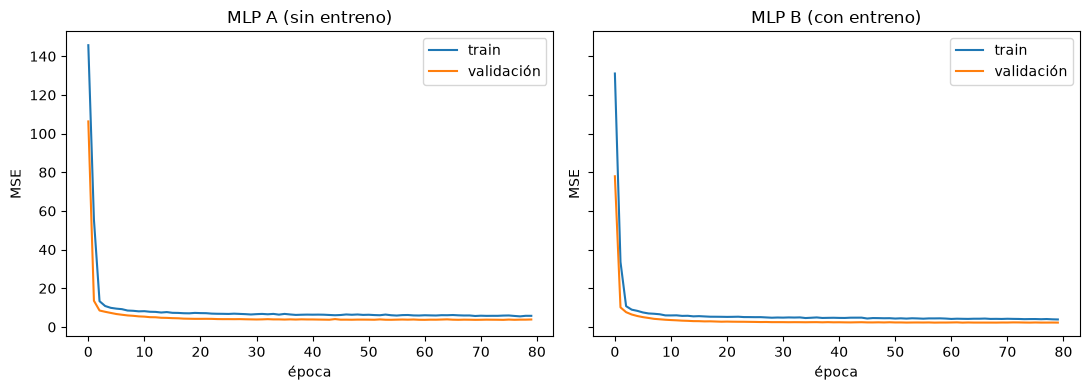

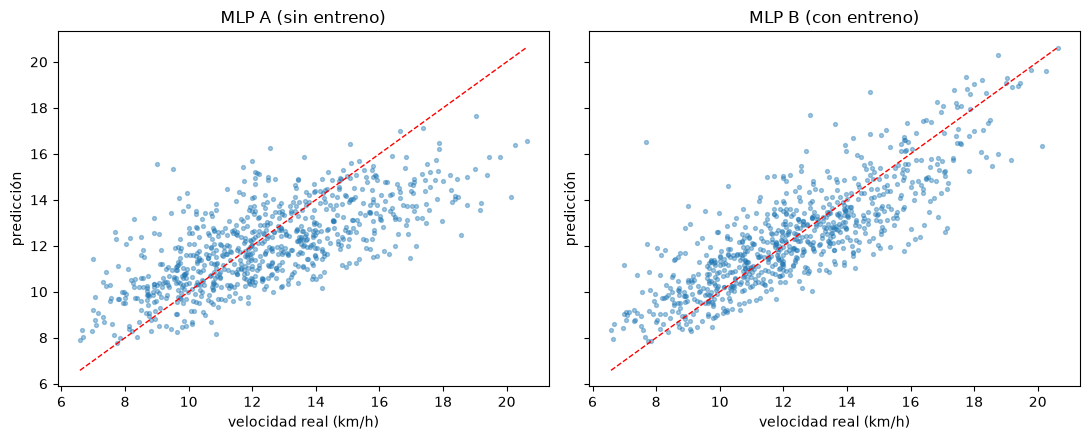

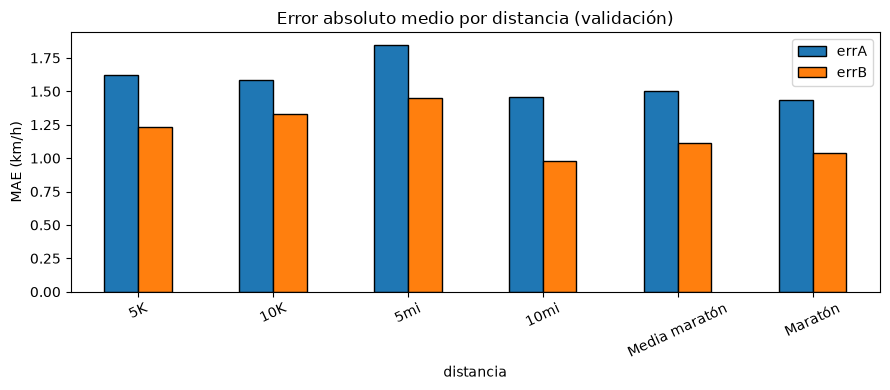

,errA,errB
distancia,,
5K,1.626,1.230
10K,1.587,1.328
5mi,1.849,1.454
10mi,1.455,0.977
Media maratón,1.499,1.113
Maratón,1.437,1.040


In [24]:
# Curvas de aprendizaje, semilla 0
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, ["MLP A (sin entreno)", "MLP B (con entreno)"]):
    h = histories[(name, SEEDS[0])]
    ax.plot(h["train"], label="train")
    ax.plot(h["val"], label="validación")
    ax.set_title(name); ax.set_xlabel("época"); ax.set_ylabel("MSE")
    ax.legend()
plt.tight_layout(); plt.show()

# Predicción vs real, validación, semilla 0
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["MLP A (sin entreno)", "MLP B (con entreno)"]):
    p = preds[(name, SEEDS[0])]
    ax.scatter(y_va, p, s=8, alpha=0.4)
    lim = [y_va.min(), y_va.max()]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(name); ax.set_xlabel("velocidad real (km/h)"); ax.set_ylabel("predicción")
plt.tight_layout(); plt.show()

# Error absoluto por distancia, B vs A (media sobre semillas)
val_d = val.copy()
val_d["errA"] = np.mean([np.abs(preds[("MLP A (sin entreno)", s)] - y_va) for s in SEEDS], axis=0)
val_d["errB"] = np.mean([np.abs(preds[("MLP B (con entreno)", s)] - y_va) for s in SEEDS], axis=0)
orden = ["5K", "10K", "5mi", "10mi", "Media maratón", "Maratón"]
g = val_d.groupby("distancia")[["errA", "errB"]].mean().reindex(orden)
g.plot(kind="bar", figsize=(9, 4), edgecolor="black")
plt.ylabel("MAE (km/h)"); plt.title("Error absoluto medio por distancia (validación)")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()
display(g.round(3))

## Resultados (validación, 5 semillas)

- **Las variables de entrenamiento sí aportan.** MLP A: RMSE 1.957 ± 0.016, R² 0.492. MLP B: RMSE 1.520 ± 0.018, R² 0.693. La diferencia pareada B − A es de unos −0.44 km/h, y B es mejor en las 5 semillas.
- **La ganancia no depende de la semilla.** La desviación entre semillas (≈0.02) es mucho menor que la diferencia entre modelos.
- **Ridge B supera al MLP B** (RMSE 1.460 vs 1.520). Con estos datos, la no linealidad de la MLP no mejora la predicción respecto a un modelo lineal con las mismas features.
- **La interacción tempo × distancia casi no aporta en Ridge** (1.460 → 1.459). El efecto de distancia sobre `tempo` que describe el paper no se ve como término de interacción en esta muestra. La ganancia del modelo B viene de los efectos principales, no de esa interacción.
- **Test no evaluado.** Este notebook sólo compara en validación. El test queda reservado para el paso final.

Limitaciones a reportar: el paper usa splines cúbicos para edad, BMI y kilometraje, y aquí no. `typical` y `max` tienen correlación 0.91; se mantienen ambas porque el modelo es no lineal, pero conviene una prueba de sensibilidad quitando una. `footwear` se incluyó en ambos modelos como atributo previo; si prefieres excluirla, el cambio es una línea.